In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(r"C:\Users\Marcelo\Documents\proyrepasodipl\LearningProject\data\raw\bank-full.csv", sep=";")

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
df.shape

(45211, 17)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [7]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [8]:
df['contact'].isnull().value_counts()

contact
False    45211
Name: count, dtype: int64

In [9]:
df['y'].value_counts(normalize = True)

y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64

In [10]:
df['job'].value_counts()

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

In [11]:
serie2=(df == 'unknown').sum()/len(df)*100
serie1= (df == 'unknown').sum()

In [12]:
data=pd.DataFrame({"cantidad": serie1, "porcentaje": serie2})

In [13]:
data.sort_values("porcentaje", ascending=False)

,cantidad,porcentaje
poutcome,36959,81.747805
contact,13020,28.798301
education,1857,4.107407
job,288,0.637013
age,0,0.000000
default,0,0.000000
balance,0,0.000000
housing,0,0.000000
marital,0,0.000000
loan,0,0.000000


In [14]:
df[['previous', 'pdays']][df['poutcome'] == "unknown"].value_counts()

previous  pdays
0         -1       36954
1          98          1
5          168         1
2          188         1
           416         1
7          528         1
Name: count, dtype: int64

In [15]:
df[['previous', 'pdays']][df['poutcome'] == "unknown"].describe()

,previous,pdays
count,36959.000000,36959.000000
mean,0.000460,-0.962039
std,0.047388,3.778887
min,0.000000,-1.000000
25%,0.000000,-1.000000
50%,0.000000,-1.000000
75%,0.000000,-1.000000
max,7.000000,528.000000


In [16]:
df['poutcome'][df['pdays'] == -1].describe()

count       36954
unique          1
top       unknown
freq        36954
Name: poutcome, dtype: object

In [17]:
df['contact'].value_counts()

contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

In [18]:
df['month'].value_counts()

month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count, dtype: int64

In [19]:
df['month'].unique()

<StringArray>
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb', 'mar', 'apr',
 'sep']
Length: 12, dtype: str

In [20]:
tabla=pd.crosstab(df['contact'], df['month']) ##genera matriz

In [21]:
lista = ['jan', 'feb', 'mar','apr','may','jun','jul','aug','sep','oct','nov','dec']

In [22]:
tabla.reindex(columns=lista)

month,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
contact,,,,,,,,,,,,
cellular,1265,2362,417,2727,5331,729,5767,5950,466,557,3540,174
telephone,129,274,53,199,460,80,852,246,66,131,379,37
unknown,9,13,7,6,7975,4532,276,51,47,50,51,3


In [23]:
pd.crosstab(df['month'], df['contact'], normalize='index')

contact,cellular,telephone,unknown
month,,,
apr,0.930082,0.067872,0.002046
aug,0.952457,0.039379,0.008164
dec,0.813084,0.172897,0.014019
feb,0.891657,0.103435,0.004908
jan,0.901639,0.091946,0.006415
jul,0.836403,0.123568,0.040029
jun,0.136491,0.014978,0.848530
mar,0.874214,0.111111,0.014675
may,0.387258,0.033416,0.579326


In [55]:
data3=pd.crosstab(df['month'], df['contact'], normalize='index')*100

In [56]:
data3=data3.reindex(lista)

In [24]:
pd.crosstab(df['contact'], df['y'], normalize='index')

y,no,yes
contact,,
cellular,0.850811,0.149189
telephone,0.865795,0.134205
unknown,0.959293,0.040707


In [25]:
pd.crosstab(df['month'], df['y'], normalize='index')

y,no,yes
month,,
apr,0.803206,0.196794
aug,0.889867,0.110133
dec,0.532710,0.467290
feb,0.833522,0.166478
jan,0.898788,0.101212
jul,0.909065,0.090935
jun,0.897772,0.102228
mar,0.480084,0.519916
may,0.932805,0.067195


In [26]:
mayo = df[df['month'] == 'may']
pd.crosstab(mayo['contact'], mayo['y'], normalize='index')

y,no,yes
contact,,
cellular,0.881261,0.118739
telephone,0.932609,0.067391
unknown,0.967273,0.032727


In [27]:
df['month'].value_counts()

month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count, dtype: int64

In [28]:
df[df['pdays'] != -1]['pdays'].describe()

count    8257.000000
mean      224.577692
std       115.344035
min         1.000000
25%       133.000000
50%       194.000000
75%       327.000000
max       871.000000
Name: pdays, dtype: float64

In [29]:
df['pdays'].describe()

count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
max        871.000000
Name: pdays, dtype: float64

In [30]:
junio = df[df['month'] == 'jun']
pd.crosstab(junio['contact'], junio['y'], normalize='index')

y,no,yes
contact,,
cellular,0.561043,0.438957
telephone,0.750000,0.250000
unknown,0.954545,0.045455


In [31]:
df['poutcome'].value_counts()

poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

Las llamadas con canal registrado como unknown tienen una tasa de aceptación menor que las de canal registrado, tanto en mayo como en junio. Los datos no explican por qué; es una pregunta para quien administra el registro.

Se analiza las columnas que tienen valores de unknown una a una. Se reviso que la columna poutcome tiene alto volumen de unknown, esto indicaria que no se contacto antes, sin embargo algunos registros tienen tienen previous y pdays con valores, por lo que si se contacto, pero no se llego a registrar (5 de 36.959). Para la variable contacto el analisis fue mas complejo, se observa que el 28.79% de sus valores es unknown y esta concentrado en mayo y junio, tras el analisis se observa que las llamadas con canal desconocido se aceptan menos (cifras: 3,3% vs 11,9% en mayo, y 4,5% en junio) que las que si tienen un canal definido al comparar con telefono o celular, no se sabe la causa de esto, pero puede servir, en caso sea un nuevo canal que se uso solo un par de meses vale la pena mencionarlo.

Tamaño (45.211 filas, 17 columnas) y tipos (7 numéricos, 10 de texto).
El desbalance: 11,7% yes, y que un modelo que dice “no” siempre acertaría 88,3% sin servir de nada.
Tener cuidado con el valor -1 en pdays, esto indica que nunca se contacto, al momento de modelar hay que tener cuidado porque al omitir estos -1 los indicadores obtenidos en el describe cambian mucho, ejemplo: con -1 el promedio es 40, sin el es 225, la diferencia es abismal y la realidad es 225.
Lo que viste con month: mayo con la aceptación más baja (6,7%) y concentra 30% de las llamadas.

proximos pasos: -1 de pdays y los unknown, y decidir qué hacer con el desbalance. Así tu yo de la semana 2 sabe por dónde seguir.

## GRAFICAS

In [32]:
from matplotlib import pyplot as plt

In [33]:
df['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [34]:
df['aceptacion'] = df['y'].replace(['no','yes'],['0','1'])

In [35]:
df['aceptacion'].value_counts()

aceptacion
0    39922
1     5289
Name: count, dtype: int64

In [36]:
df['aceptacion']=df['aceptacion'].astype(int)

In [37]:
tasa=df.groupby('month')['aceptacion'].mean()
tasa = tasa.reindex(lista)

In [40]:
tasa = tasa * 100

In [42]:
cantidad=df.groupby('month')['aceptacion'].count()
cantidad = cantidad.reindex(lista)

<Axes: title={'center': 'Evolucion de tasas'}, xlabel='month'>

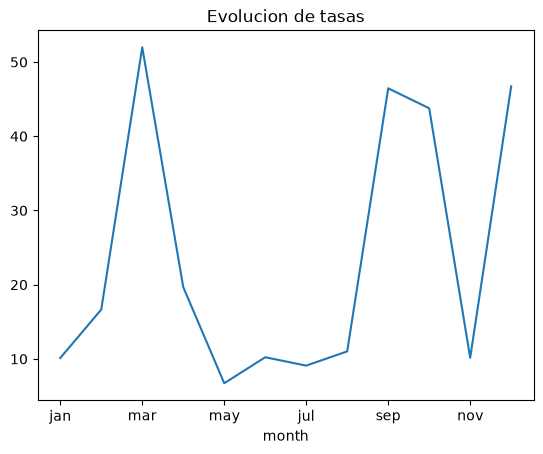

In [41]:
tasa.plot(kind="line", x='month', y='tasa', title="Evolucion de tasas")

<Axes: title={'center': 'Evolucion de tasas'}, xlabel='month'>

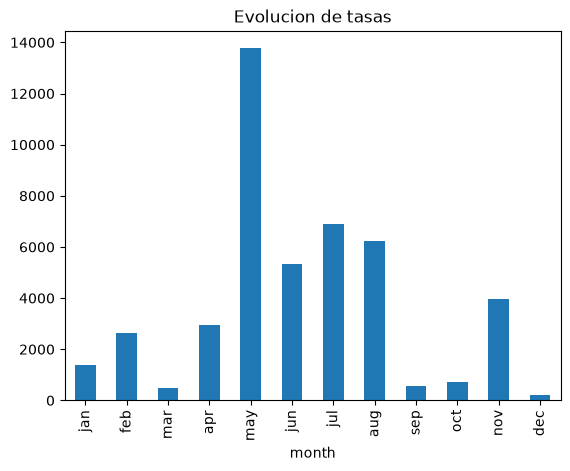

In [43]:
cantidad.plot(kind="bar", title="Evolucion de tasas")

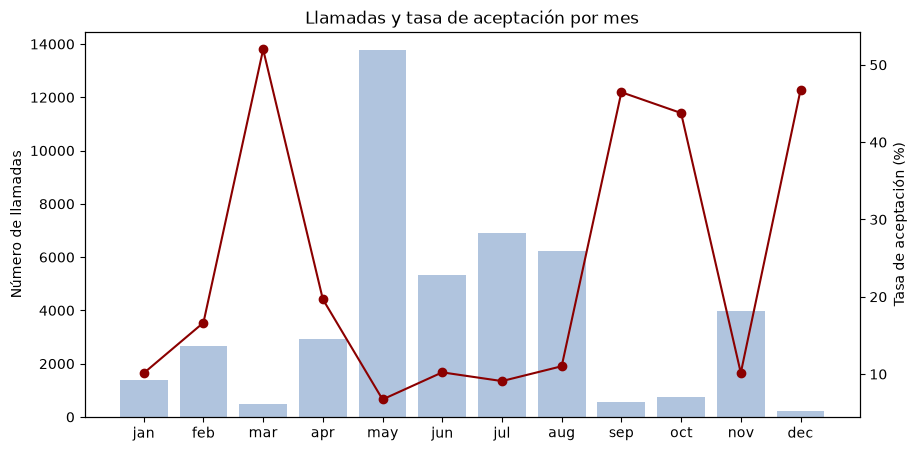

In [44]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

ax1.bar(cantidad.index, cantidad.values, color="lightsteelblue")
ax1.set_ylabel("Número de llamadas")

ax2.plot(tasa.index, tasa.values, color="darkred", marker="o")
ax2.set_ylabel("Tasa de aceptación (%)")

ax1.set_title("Llamadas y tasa de aceptación por mes")
plt.show()

In [57]:
data3

contact,cellular,telephone,unknown
month,,,
jan,90.163934,9.194583,0.641483
feb,89.165723,10.343526,0.490751
mar,87.421384,11.111111,1.467505
apr,93.008186,6.787176,0.204638
may,38.725846,3.341566,57.932588
jun,13.649129,1.497847,84.853024
jul,83.640319,12.356780,4.002901
aug,95.245718,3.937890,0.816392
sep,80.483592,11.398964,8.117444


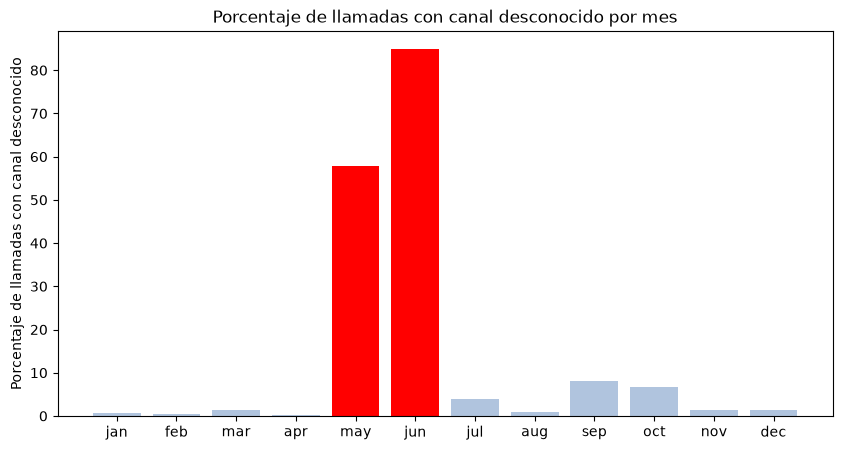

In [ ]:

colores = ["red" if d in ["may", "jun"] else "lightsteelblue" for d in data3.index]
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(data3.index, data3.unknown, color=colores)
ax1.set_ylabel("Llamadas con canal desconocido (%)")

ax1.set_title("Porcentaje de llamadas con canal desconocido por mes")
plt.show()

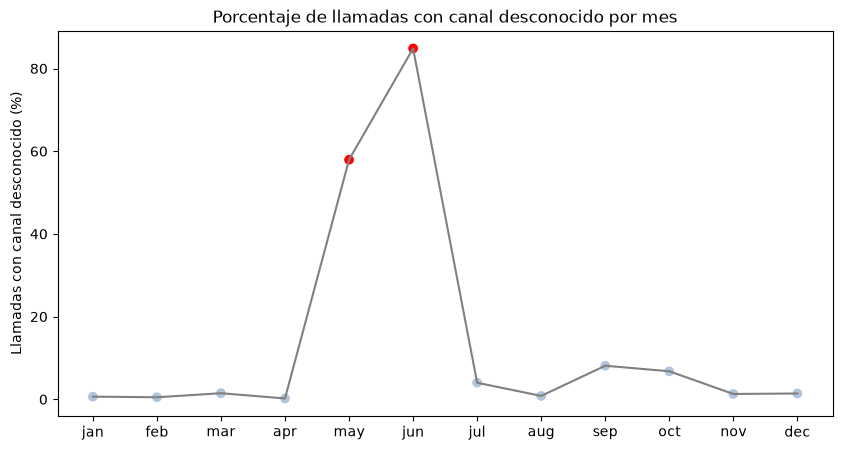

In [64]:
colores = ["red" if d in ["may", "jun"] else "lightsteelblue" for d in data3.index]
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(data3.index, data3.unknown, color="gray")
ax1.scatter(data3.index, data3.unknown, color=colores)
ax1.set_ylabel("Llamadas con canal desconocido (%)")

ax1.set_title("Porcentaje de llamadas con canal desconocido por mes")
plt.show()

In [78]:
df1 = df[df['month'].isin(['may','jun'])]
tasa1=df1.groupby(['month','contact'])['aceptacion'].mean().unstack() *100
tasa1 = tasa1.reindex(lista)

In [79]:
tasa1

contact,cellular,telephone,unknown
month,,,
jan,NaN,NaN,NaN
feb,NaN,NaN,NaN
mar,NaN,NaN,NaN
apr,NaN,NaN,NaN
may,11.873945,6.73913,3.272727
jun,43.895748,25.00000,4.545455
jul,NaN,NaN,NaN
aug,NaN,NaN,NaN
sep,NaN,NaN,NaN


In [80]:
df1.groupby(["month", "contact"]).size()

month  contact  
jun    cellular      729
       telephone      80
       unknown      4532
may    cellular     5331
       telephone     460
       unknown      7975
dtype: int64

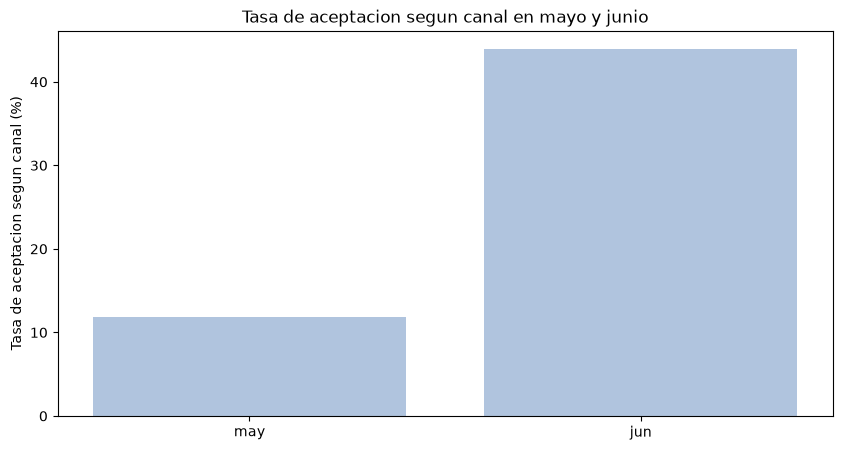

In [ ]:
#colores = ["red" if d in ["may", "jun"] else "lightsteelblue" for d in data3.index]
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(tasa1.index, tasa1.cellular, color="lightsteelblue")
ax1.bar(tasa1.index, tasa1.telephone, color="lightsteelblue")
ax1.bar(tasa1.index, tasa1.unknown, color="lightsteelblue")
ax1.set_ylabel("Tasa de aceptacion segun canal (%)")

ax1.set_title("Tasa de aceptacion segun canal en mayo y junio")
plt.show()

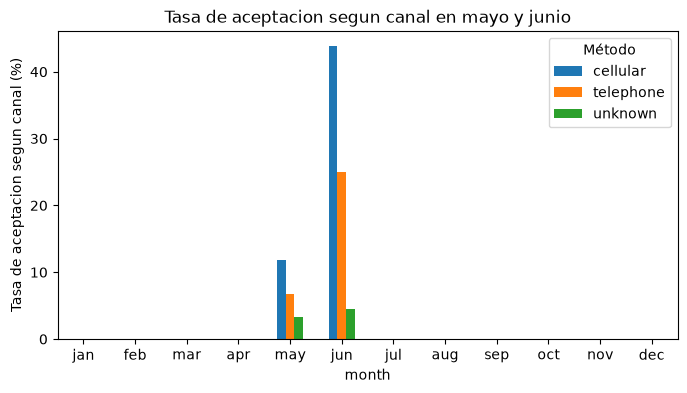

In [85]:
fig, ax1 = plt.subplots(figsize=(8, 4))
tasa1.plot(kind="bar", ax=ax1, rot=0)
ax1.set_ylabel("Tasa de aceptacion segun canal (%)")
ax1.set_title("Tasa de aceptacion segun canal en mayo y junio")
ax1.legend(title="Método")
plt.show()

## Notas de gráficos (pandas y matplotlib)

- **Dos formas de graficar.** `df.plot(kind=...)` es el atajo de pandas y `ax.bar(...)` o `ax.plot(...)` es matplotlib directo. Se combinan: `ax = df.plot(...)` devuelve el eje y luego se retoca con `ax.set_title(...)`.
- **Argumentos con y sin nombre.** Sin nombre, el orden importa (en `bar`: primero `x`, luego `height`). Con nombre, el orden da igual, pero los posicionales van primero. `color` siempre va con nombre (`color="..."`).
- **Dos series en un mismo gráfico.** Se puede sin juntarlas en un DataFrame (`ax1.bar(...)` y `ax2.plot(...)`, o `secondary_y=True`). Con series sueltas, pandas las coloca por posición, así que deben tener el mismo índice y el mismo orden (`reindex`) antes de graficar.
- **Meses o etiquetas faltantes.** Al construir un DataFrame, pandas alinea por etiqueta y la que falta queda como `NaN` (hueco en el gráfico).
- **Colores dinámicos.** Una list comprehension arma un color por punto: `["red" if d in [...] else "lightsteelblue" for d in serie.index]`. En barras se pasa a `color=`; en líneas se combinan `ax.plot` y `ax.scatter`.
- **`fig` y `ax`.** `fig` es el lienzo y `ax` es un recuadro de gráfico. `twinx()` agrega un segundo eje vertical al mismo recuadro; `plt.subplots(1, 2)` crea dos recuadros separados.
- **Agrupar por dos columnas.** `groupby(["a", "b"])` genera un índice de dos niveles; `unstack()` pasa el segundo nivel a columnas y permite barras agrupadas con `.plot(kind="bar")`.
- **`NaN` tras un `reindex`.** Casi siempre significa que las etiquetas no coinciden con el índice.
- **Regla práctica.** `.plot` para lo estándar y `ax.` para controlar cada detalle.